In [3]:
!pip install --quiet statsbombpy pandas mplsoccer matplotlib
from statsbombpy import sb
import pandas as pd

# 1. Tüm müsabakaları listeleyip 2022 Dünya Kupası'nı bulalım
competitions = sb.competitions()

# 2022 Dünya Kupası bilgilerini filtreleme (competition_id = 43, season_id = 106 genelde 2022 WC'dir)
wc_matches = sb.matches(competition_id=43, season_id=106)

# Maç listesinde Arjantin - Fransa (Final) maçını bulalım
final_match = wc_matches[wc_matches['home_team'].str.contains('Argentina') &
                         wc_matches['away_team'].str.contains('France')]

match_id = final_match['match_id'].values[0]
print(f"2022 Dünya Kupası Finali Maç ID'si: {match_id}")

# 2. Maçın ham olay (event) verisini ve kadrolarını çekme
events = sb.events(match_id=match_id)
lineups = sb.lineups(match_id=match_id)

# 3. DataFrame hakkında ilk inceleme
print(f"\nToplam Olay (Event) Sayısı: {len(events)}")
print("\nOlay Türleri (Event Types):")
print(events['type'].value_counts().head(10))

/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


2022 Dünya Kupası Finali Maç ID'si: 3869685


/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(



Toplam Olay (Event) Sayısı: 4407

Olay Türleri (Event Types):
type
Pass              1263
Ball Receipt*     1114
Carry              940
Pressure           361
Ball Recovery      115
Duel                98
Dribble             54
Block               50
Foul Committed      48
Clearance           45
Name: count, dtype: int64


In [4]:
# Maçtaki takımların adlarını kontrol edelim
print(events['team'].unique())

['Argentina' 'France']


In [5]:
# 1. Fransa takımının adını DataFrame'den dinamik olarak çekelim
france_name = [t for t in events['team'].unique() if 'France' in t][0]
print(f"İncelenen Takım: {france_name}")

# 2. Sadece Fransa'nın başarılı paslarını filtreleyelim (pass_outcome boş olanlar başarılıdır)
france_passes = events[
    (events['type'] == 'Pass') &
    (events['team'] == france_name) &
    (events['pass_outcome'].isnull())
].copy()

# Oyuncu isimlerini temiz string formatına getirelim
france_passes['player'] = france_passes['player'].apply(lambda x: str(x))
france_passes['pass_recipient'] = france_passes['pass_recipient'].apply(lambda x: str(x))

# 3. Hangi oyuncu kime kaç pas atmış? (Pas matrisi ve ikililer)
pass_pairs = france_passes.groupby(['player', 'pass_recipient']).size().reset_index(name='pass_count')
pass_pairs = pass_pairs.sort_values(by='pass_count', ascending=False)

# İlk 10 en yoğun pas ikilisini ekrana yazdıralım
print("\nFransa Maçındaki En Yoğun 10 Pas İkilisi:")
print(pass_pairs.head(10).to_string(index=False))

İncelenen Takım: France

Fransa Maçındaki En Yoğun 10 Pas İkilisi:
                         player                  pass_recipient  pass_count
                 Raphaël Varane        Dayotchanculle Upamecano          16
                   Jules Koundé                  Raphaël Varane          15
       Dayotchanculle Upamecano                  Raphaël Varane          14
                 Raphaël Varane                    Jules Koundé          12
       Dayotchanculle Upamecano Theo Bernard François Hernández          10
      Aurélien Djani Tchouaméni                   Adrien Rabiot           9
      Aurélien Djani Tchouaméni        Dayotchanculle Upamecano           9
      Aurélien Djani Tchouaméni                    Jules Koundé           8
                  Adrien Rabiot       Aurélien Djani Tchouaméni           8
Theo Bernard François Hernández            Kylian Mbappé Lottin           8


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# 1. Oyuncuların Ortalama Konumlarını (X, Y) Hesaplama
# location sütunu [x, y] listesi tutar; bunların ortalamasını alıyoruz
france_passes['x'] = france_passes['location'].apply(lambda loc: loc[0] if isinstance(loc, list) and len(loc) > 0 else np.nan)
france_passes['y'] = france_passes['location'].apply(lambda loc: loc[1] if isinstance(loc, list) and len(loc) > 1 else np.nan)

avg_locs = france_passes.groupby('player').agg({
    'x': 'mean',
    'y': 'mean'
}).reset_index()

# Oyuncu bazlı toplam pas sayıları (düğüm büyüklüğü için)
pass_count = france_passes.groupby('player').size().reset_index(name='total_passes')
avg_locs = avg_locs.merge(pass_count, on='player')

# 2. İkili Pas Frekanslarını Hazırlama
pass_pairs = france_passes.groupby(['player', 'pass_recipient']).size().reset_index(name='pass_count')
pass_pairs = pass_pairs.merge(avg_locs[['player', 'x', 'y']], on='player', suffixes=('', '_start'))
pass_pairs = pass_pairs.merge(avg_locs[['player', 'x', 'y']], left_on='pass_recipient', right_on='player', suffixes=('', '_end'))

# 3. mplsoccer ile Sahayı ve Grafiği Çizme
pitch = Pitch(pitch_type='statsbomb', pitch_color='#22312b', line_color='#c7dccc',
              goal_type='box', bg_color='#121212')

fig, ax = pitch.draw(figsize=(12, 8))

# A. Pas Bağlantılarını (Çizgiler) Çizme
# Sadece belirli bir eşiğin üzerindeki pas trafiğini gösterelim (örn. 3 pastan fazla)
for _, row in pass_pairs.iterrows():
    if row['pass_count'] > 2:
        ax.plot([row['x_start'], row['x_end']], [row['y_start'], row['y_end']],
                color='#79b791',
                alpha=min(row['pass_count'] / 10, 1.0), # Yoğunluğa göre şeffaflık
                linewidth=row['pass_count'] / 2.5,     # Pas sayısına göre çizgi kalınlığı
                zorder=2)

# B. Oyuncu Ortalama Konumlarını (Düğümler) Çizme
ax.scatter(avg_locs['x'], avg_locs['y'],
           s=avg_locs['total_passes'] * 12, # Toplam pas sayısına göre daire boyutu
           color='#ea6962', edgecolors='white', linewidth=1.5, zorder=3)

# C. Oyuncu İsimlerini Ekleme (Soyadları)
for _, row in avg_locs.iterrows():
    name = row['player'].split()[-1] # Sadece soyadını alalım
    ax.text(row['x'], row['y'] - 2.8, name,
            color='white', fontsize=10, fontweight='bold',
            ha='center', va='center', zorder=4)

plt.title('Fransa - 2022 Dünya Kupası Finali Pas Ağı', color='white', fontsize=16, pad=20)
plt.show()

TypeError: BasePitchSoccer.__init__() got an unexpected keyword argument 'bg_color'

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# 1. Fransa takımının adını dinamik olarak bulma
france_name = [t for t in events['team'].unique() if 'France' in t][0]

# 2. Fransa'nın başarılı paslarını filtreleme
france_passes = events[
    (events['type'] == 'Pass') &
    (events['team'] == france_name) &
    (events['pass_outcome'].isnull())
].copy()

# 3. Koordinatları (X, Y) güvenli bir şekilde çıkarma
def extract_coord(loc, idx):
    if isinstance(loc, (list, np.ndarray)) and len(loc) > idx:
        return float(loc[idx])
    return np.nan

france_passes['x'] = france_passes['location'].apply(lambda l: extract_coord(l, 0))
france_passes['y'] = france_passes['location'].apply(lambda l: extract_coord(l, 1))

# NaN (eksik) değerleri temizleme
france_passes = france_passes.dropna(subset=['x', 'y'])

# Oyuncu isimlerini temizleme
france_passes['player'] = france_passes['player'].apply(lambda x: str(x))
france_passes['pass_recipient'] = france_passes['pass_recipient'].apply(lambda x: str(x))

# 4. Ortalama Konum Hesabı
avg_locs = france_passes.groupby('player').agg({
    'x': 'mean',
    'y': 'mean'
}).reset_index()

pass_count = france_passes.groupby('player').size().reset_index(name='total_passes')
avg_locs = avg_locs.merge(pass_count, on='player')

# 5. İkili Pas Frekansları
pass_pairs = france_passes.groupby(['player', 'pass_recipient']).size().reset_index(name='pass_count')
pass_pairs = pass_pairs.merge(avg_locs[['player', 'x', 'y']], on='player', suffixes=('', '_start'))
pass_pairs = pass_pairs.merge(avg_locs[['player', 'x', 'y']], left_on='pass_recipient', right_on='player', suffixes=('', '_end'))

# 6. mplsoccer ile Çizim
pitch = Pitch(pitch_type='statsbomb', pitch_color='#22312b', line_color='#c7dccc',
              goal_type='box', bg_color='#121212')

fig, ax = pitch.draw(figsize=(12, 8))

# Pas çizgileri
for _, row in pass_pairs.iterrows():
    if row['pass_count'] > 2:
        ax.plot([row['x_start'], row['x_end']], [row['y_start'], row['y_end']],
                color='#79b791',
                alpha=min(row['pass_count'] / 10, 1.0),
                linewidth=row['pass_count'] / 2.5,
                zorder=2)

# Oyuncu daireleri
ax.scatter(avg_locs['x'], avg_locs['y'],
           s=avg_locs['total_passes'] * 12,
           color='#ea6962', edgecolors='white', linewidth=1.5, zorder=3)

# Oyuncu soyadları
for _, row in avg_locs.iterrows():
    name = row['player'].split()[-1]
    ax.text(row['x'], row['y'] - 2.8, name,
            color='white', fontsize=10, fontweight='bold',
            ha='center', va='center', zorder=4)

plt.title('Fransa - 2022 Dünya Kupası Finali Pas Ağı', color='white', fontsize=16, pad=20)
plt.show()

TypeError: BasePitchSoccer.__init__() got an unexpected keyword argument 'bg_color'

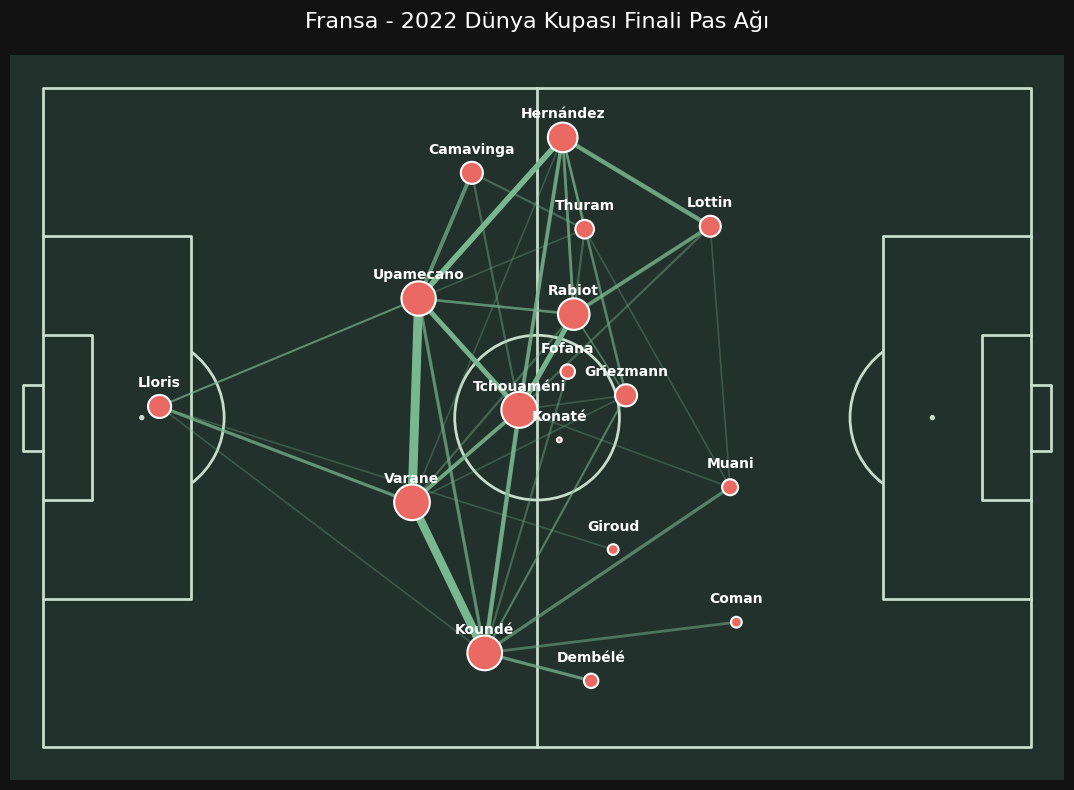

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# 1. Fransa takımının adını dinamik olarak bulma
france_name = [t for t in events['team'].unique() if 'France' in t][0]

# 2. Fransa'nın başarılı paslarını filtreleme
france_passes = events[
    (events['type'] == 'Pass') &
    (events['team'] == france_name) &
    (events['pass_outcome'].isnull())
].copy()

# 3. Koordinatları (X, Y) güvenli bir şekilde çıkarma
def extract_coord(loc, idx):
    if isinstance(loc, (list, np.ndarray)) and len(loc) > idx:
        return float(loc[idx])
    return np.nan

france_passes['x'] = france_passes['location'].apply(lambda l: extract_coord(l, 0))
france_passes['y'] = france_passes['location'].apply(lambda l: extract_coord(l, 1))

# NaN (eksik) değerleri temizleme
france_passes = france_passes.dropna(subset=['x', 'y'])

# Oyuncu isimlerini temizleme
france_passes['player'] = france_passes['player'].apply(lambda x: str(x))
france_passes['pass_recipient'] = france_passes['pass_recipient'].apply(lambda x: str(x))

# 4. Ortalama Konum Hesabı
avg_locs = france_passes.groupby('player').agg({
    'x': 'mean',
    'y': 'mean'
}).reset_index()

pass_count = france_passes.groupby('player').size().reset_index(name='total_passes')
avg_locs = avg_locs.merge(pass_count, on='player')

# 5. İkili Pas Frekansları (Sütunları önceden manuel olarak adlandırarak hatayı engelliyoruz)
pass_pairs = france_passes.groupby(['player', 'pass_recipient']).size().reset_index(name='pass_count')

# Başlangıç konumlarını ekleme
start_locs = avg_locs[['player', 'x', 'y']].rename(columns={'x': 'x_start', 'y': 'y_start'})
pass_pairs = pass_pairs.merge(start_locs, on='player', how='left')

# Bitiş konumlarını ekleme
end_locs = avg_locs[['player', 'x', 'y']].rename(columns={'player': 'pass_recipient', 'x': 'x_end', 'y': 'y_end'})
pass_pairs = pass_pairs.merge(end_locs, on='pass_recipient', how='left')

# 6. mplsoccer ile Çizim
pitch = Pitch(pitch_type='statsbomb', pitch_color='#22312b', line_color='#c7dccc',
              goal_type='box')

fig, ax = pitch.draw(figsize=(12, 8))
fig.set_facecolor('#121212') # Arka plan rengini belirliyoruz

# Pas çizgileri
for _, row in pass_pairs.iterrows():
    if row['pass_count'] > 2:
        ax.plot([row['x_start'], row['x_end']], [row['y_start'], row['y_end']],
                color='#79b791',
                alpha=min(row['pass_count'] / 10, 1.0),
                linewidth=row['pass_count'] / 2.5,
                zorder=2)

# Oyuncu daireleri
ax.scatter(avg_locs['x'], avg_locs['y'],
           s=avg_locs['total_passes'] * 12,
           color='#ea6962', edgecolors='white', linewidth=1.5, zorder=3)

# Oyuncu soyadları
for _, row in avg_locs.iterrows():
    name = row['player'].split()[-1]
    ax.text(row['x'], row['y'] - 2.8, name,
            color='white', fontsize=10, fontweight='bold',
            ha='center', va='center', zorder=4)

plt.title('Fransa - 2022 Dünya Kupası Finali Pas Ağı', color='white', fontsize=16, pad=20)
plt.show()

İncelenen Takım: Argentina


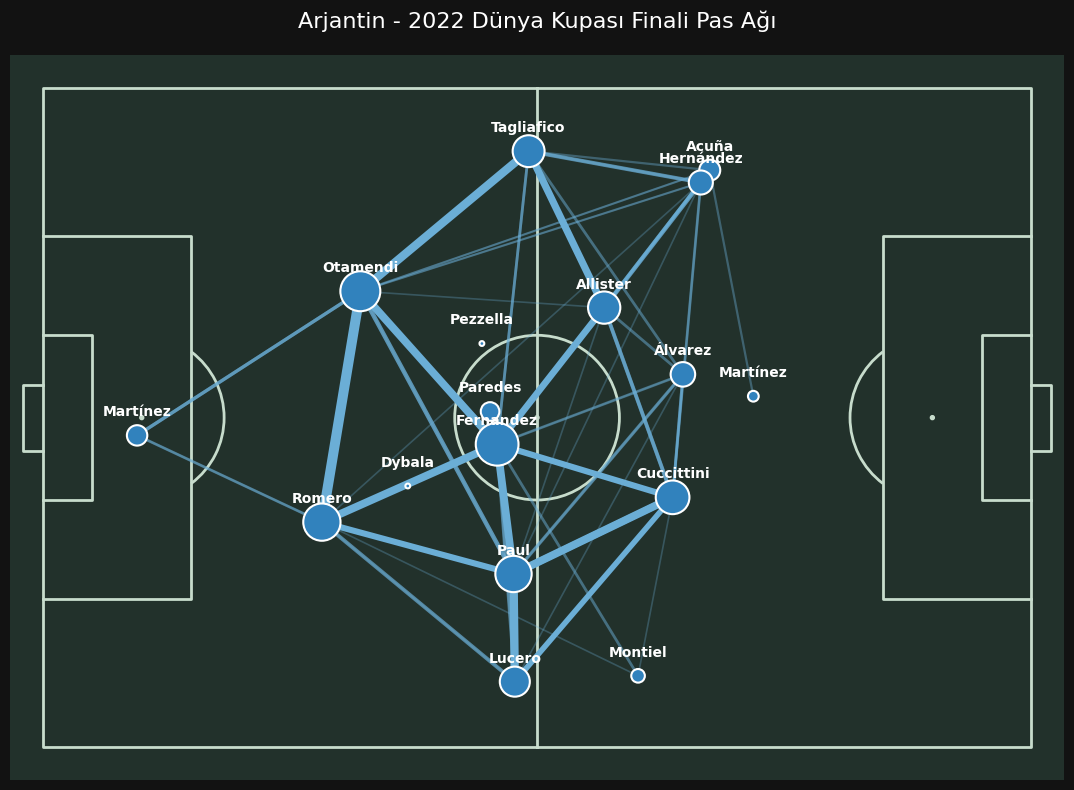

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mplsoccer import Pitch

# 1. Arjantin takımının adını dinamik olarak bulma
arg_name = [t for t in events['team'].unique() if 'Argentina' in t][0]
print(f"İncelenen Takım: {arg_name}")

# 2. Arjantin'in başarılı paslarını filtreleme
arg_passes = events[
    (events['type'] == 'Pass') &
    (events['team'] == arg_name) &
    (events['pass_outcome'].isnull())
].copy()

# 3. Koordinatları (X, Y) güvenli bir şekilde çıkarma
def extract_coord(loc, idx):
    if isinstance(loc, (list, np.ndarray)) and len(loc) > idx:
        return float(loc[idx])
    return np.nan

arg_passes['x'] = arg_passes['location'].apply(lambda l: extract_coord(l, 0))
arg_passes['y'] = arg_passes['location'].apply(lambda l: extract_coord(l, 1))

# NaN (eksik) değerleri temizleme
arg_passes = arg_passes.dropna(subset=['x', 'y'])

# Oyuncu isimlerini temizleme
arg_passes['player'] = arg_passes['player'].apply(lambda x: str(x))
arg_passes['pass_recipient'] = arg_passes['pass_recipient'].apply(lambda x: str(x))

# 4. Ortalama Konum Hesabı
arg_avg_locs = arg_passes.groupby('player').agg({
    'x': 'mean',
    'y': 'mean'
}).reset_index()

arg_pass_count = arg_passes.groupby('player').size().reset_index(name='total_passes')
arg_avg_locs = arg_avg_locs.merge(arg_pass_count, on='player')

# 5. İkili Pas Frekansları (Sütunları önceden manuel olarak adlandırarak hatayı engelliyoruz)
arg_pass_pairs = arg_passes.groupby(['player', 'pass_recipient']).size().reset_index(name='pass_count')

# Başlangıç konumlarını ekleme
start_locs = arg_avg_locs[['player', 'x', 'y']].rename(columns={'x': 'x_start', 'y': 'y_start'})
arg_pass_pairs = arg_pass_pairs.merge(start_locs, on='player', how='left')

# Bitiş konumlarını ekleme
end_locs = arg_avg_locs[['player', 'x', 'y']].rename(columns={'player': 'pass_recipient', 'x': 'x_end', 'y': 'y_end'})
arg_pass_pairs = arg_pass_pairs.merge(end_locs, on='pass_recipient', how='left')

# 6. mplsoccer ile Arjantin Çizimi
pitch = Pitch(pitch_type='statsbomb', pitch_color='#22312b', line_color='#c7dccc',
              goal_type='box')

fig, ax = pitch.draw(figsize=(12, 8))
fig.set_facecolor('#121212') # Arka plan rengini belirliyoruz

# Pas çizgileri
for _, row in arg_pass_pairs.iterrows():
    if row['pass_count'] > 2:
        ax.plot([row['x_start'], row['x_end']], [row['y_start'], row['y_end']],
                color='#6baed6', # Arjantin için mavi tonu
                alpha=min(row['pass_count'] / 10, 1.0),
                linewidth=row['pass_count'] / 2.5,
                zorder=2)

# Oyuncu daireleri
ax.scatter(arg_avg_locs['x'], arg_avg_locs['y'],
           s=arg_avg_locs['total_passes'] * 12,
           color='#3182bd', edgecolors='white', linewidth=1.5, zorder=3)

# Oyuncu soyadları
for _, row in arg_avg_locs.iterrows():
    name = row['player'].split()[-1]
    ax.text(row['x'], row['y'] - 2.8, name,
            color='white', fontsize=10, fontweight='bold',
            ha='center', va='center', zorder=4)

plt.title('Arjantin - 2022 Dünya Kupası Finali Pas Ağı', color='white', fontsize=16, pad=20)
plt.show()

In [13]:
import networkx as nx

def calculate_centrality(passes_df, team_name):
    # İlgili takımın pas çiftlerini ve sayılarını çıkarma
    pairs = passes_df.groupby(['player', 'pass_recipient']).size().reset_index(name='weight')

    # NetworkX Yönlü Graf (Directed Graph) oluşturma
    G = nx.DiGraph()
    for _, row in pairs.iterrows():
        G.add_edge(row['player'], row['pass_recipient'], weight=row['weight'])

    # Merkezilik Skorlarını Hesaplama
    # In-degree (pas alınan) ve Out-degree (pas atılan)
    in_deg = nx.in_degree_centrality(G)
    betweenness = nx.betweenness_centrality(G, weight='weight')

    # Veriyi DataFrame'e dönüştürüp sıralama
    cent_df = pd.DataFrame({
        'Oyuncu': list(in_deg.keys()),
        'Pas Alma Merkeziliği': list(in_deg.values()),
        'Aradalık (Köprü) Skoru': [betweenness.get(node, 0) for node in in_deg.keys()]
    })

    print(f"\n--- {team_name} En Kritik Pas Düğümleri (Merkezilik Sıralaması) ---")
    print(cent_df.sort_values(by='Aradalık (Köprü) Skoru', ascending=False).head(5).to_string(index=False))

# Fransa için çalıştırma
calculate_centrality(france_passes, "Fransa")

# Arjantin için çalıştırma
calculate_centrality(arg_passes, "Arjantin")


--- Fransa En Kritik Pas Düğümleri (Merkezilik Sıralaması) ---
              Oyuncu  Pas Alma Merkeziliği  Aradalık (Köprü) Skoru
        Jules Koundé                0.8750                0.156376
Kylian Mbappé Lottin                0.6250                0.115099
   Randal Kolo Muani                0.6250                0.101940
      Raphaël Varane                0.6875                0.100095
       Marcus Thuram                0.5625                0.097440

--- Arjantin En Kritik Pas Düğümleri (Merkezilik Sıralaması) ---
                        Oyuncu  Pas Alma Merkeziliği  Aradalık (Köprü) Skoru
           Marcos Javier Acuña                0.6875                0.268785
       Nicolás Hernán Otamendi                0.7500                0.194172
       Lautaro Javier Martínez                0.3125                0.181285
Lionel Andrés Messi Cuccittini                0.6875                0.166047
                Enzo Fernandez                0.9375                0.145228


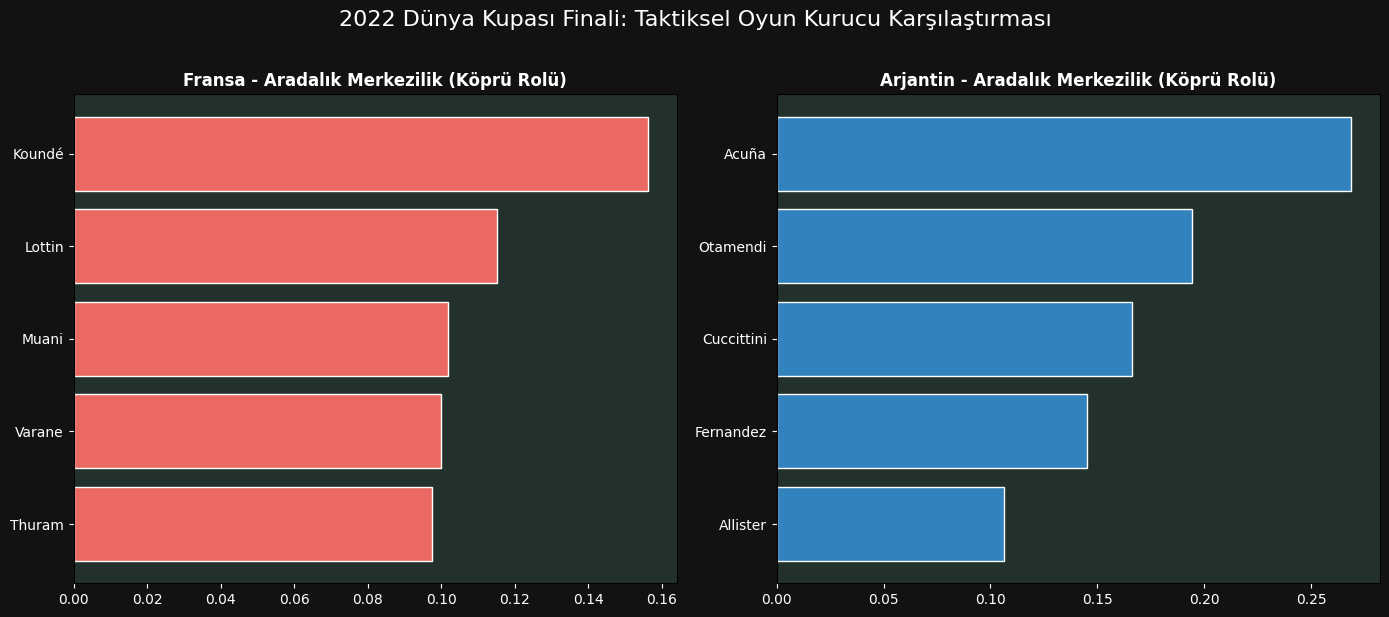

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import networkx as nx

# Fonksiyonu güncelleyip skorları sözlük (dict) olarak döndürelim
def get_centrality_dict(passes_df):
    pairs = passes_df.groupby(['player', 'pass_recipient']).size().reset_index(name='weight')
    G = nx.DiGraph()
    for _, row in pairs.iterrows():
        G.add_edge(row['player'], row['pass_recipient'], weight=row['weight'])
    betweenness = nx.betweenness_centrality(G, weight='weight')
    # Sadece soyadlarını alarak sadeleştirelim
    return {player.split()[-1]: score for player, score in betweenness.items()}

fr_cent = get_centrality_dict(france_passes)
arg_cent = get_centrality_dict(arg_passes)

# En yüksek skorlu ilk 5 oyuncuyu seçelim
fr_top = sorted(fr_cent.items(), key=lambda x: x[1], reverse=True)[:5]
arg_top = sorted(arg_cent.items(), key=lambda x: x[1], reverse=True)[:5]

# Matplotlib ile yan yana bar grafiği çizimi
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), facecolor='#121212')
for ax in [ax1, ax2]:
    ax.set_facecolor('#22312b')
    ax.tick_params(colors='white')
    ax.xaxis.label.set_color('white')
    ax.yaxis.label.set_color('white')
    ax.title.set_color('white')

# Fransa Grafiği
players_fr, scores_fr = zip(*fr_top)
ax1.barh(players_fr, scores_fr, color='#ea6962', edgecolor='white')
ax1.set_title('Fransa - Aradalık Merkezilik (Köprü Rolü)', fontsize=12, fontweight='bold')
ax1.invert_yaxis() # En yüksek skor üstte dursun

# Arjantin Grafiği
players_arg, scores_arg = zip(*arg_top)
ax2.barh(players_arg, scores_arg, color='#3182bd', edgecolor='white')
ax2.set_title('Arjantin - Aradalık Merkezilik (Köprü Rolü)', fontsize=12, fontweight='bold')
ax2.invert_yaxis()

plt.suptitle('2022 Dünya Kupası Finali: Taktiksel Oyun Kurucu Karşılaştırması', color='white', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()